# 07 — Monitoring and Stress Testing

A validated score can degrade without throwing an error. This notebook builds a reference window,
demonstrates a quiet control comparison, injects a transparent adverse scenario, and converts drift
signals into an operating response.

PSI bands used here: below 0.10 = stable, 0.10–0.25 = review, and 0.25+ = material. These are alert
bands, not proof that predictive performance has changed.

**Window design:** a 20,000-row training sample is the fixed reference and an equally sized
validation sample is the control/current window. This is a reproducible demonstration, not a true
production timeline. A deployed monitor would use dated, non-overlapping windows and retain the
approved reference snapshot with the model version.

In [1]:
from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def find_project_root() -> Path:
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Run this notebook from the project or notebook directory")


PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from credit_risk_champion_challenger.constants import (  # noqa: E402
    CATEGORICAL_FEATURES,
    MODEL_FEATURES,
    NUMERIC_FEATURES,
)
from credit_risk_champion_challenger.evaluation import evaluate_binary_classifier  # noqa: E402
from credit_risk_champion_challenger.monitoring import drift_report, numeric_psi  # noqa: E402

usecols = ["SK_ID_CURR", "TARGET", *MODEL_FEATURES]
raw = pd.read_csv(PROJECT_ROOT / "data" / "raw" / "application_train.csv", usecols=usecols)
assignments = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "split_assignments.csv")
data = raw.merge(assignments, on="SK_ID_CURR", validate="one_to_one")

reference = data.query("split == 'train'").sample(20_000, random_state=42).reset_index(drop=True)
control = data.query("split == 'val'").sample(20_000, random_state=42).reset_index(drop=True)
reference.shape, control.shape

((20000, 13), (20000, 13))

## 1. Control window

Train-versus-validation sampling variation provides a useful false-alarm check. Because this is a
random split, the control window should normally remain quiet.

In [2]:
control_report = drift_report(
    reference,
    control,
    numeric=list(NUMERIC_FEATURES),
    categorical=list(CATEGORICAL_FEATURES),
)
control_report.style.format({"psi": "{:.4f}"}).background_gradient(subset=["psi"], cmap="YlOrRd")

,feature,kind,psi,status
0,EXT_SOURCE_2,numeric,0.0018,stable
1,EXT_SOURCE_1,numeric,0.0016,stable
2,AMT_ANNUITY,numeric,0.0015,stable
3,NAME_EDUCATION_TYPE,categorical,0.0011,stable
4,DAYS_BIRTH,numeric,0.0010,stable
5,EXT_SOURCE_3,numeric,0.0007,stable
6,AMT_CREDIT,numeric,0.0007,stable
7,NAME_INCOME_TYPE,categorical,0.0006,stable
8,DAYS_EMPLOYED,numeric,0.0004,stable
9,AMT_INCOME_TOTAL,numeric,0.0002,stable


## 2. Transparent adverse scenario

The synthetic scenario represents higher requested credit, lower income, weaker external bureau
scores, and a changed income-source mix. It is deliberately simple and reproducible; it is not a
claim about a particular macroeconomic forecast.

In [3]:
stressed = control.copy()
stressed["AMT_CREDIT"] *= 1.25
stressed["AMT_INCOME_TOTAL"] *= 0.90
for column in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"]:
    stressed[column] = (stressed[column] * 0.85).clip(0, 1)

rng = np.random.default_rng(42)
income_shift = rng.random(len(stressed)) < 0.15
stressed.loc[income_shift, "NAME_INCOME_TYPE"] = "Commercial associate"

stress_report = drift_report(
    reference,
    stressed,
    numeric=list(NUMERIC_FEATURES),
    categorical=list(CATEGORICAL_FEATURES),
)
stress_report.style.format({"psi": "{:.4f}"}).background_gradient(subset=["psi"], cmap="YlOrRd")

,feature,kind,psi,status
0,EXT_SOURCE_2,numeric,1.7924,material
1,EXT_SOURCE_3,numeric,0.8006,material
2,EXT_SOURCE_1,numeric,0.4847,material
3,AMT_INCOME_TOTAL,numeric,0.3474,material
4,AMT_CREDIT,numeric,0.1933,review
5,NAME_INCOME_TYPE,categorical,0.0714,stable
6,AMT_ANNUITY,numeric,0.0015,stable
7,NAME_EDUCATION_TYPE,categorical,0.0011,stable
8,DAYS_BIRTH,numeric,0.0010,stable
9,DAYS_EMPLOYED,numeric,0.0004,stable


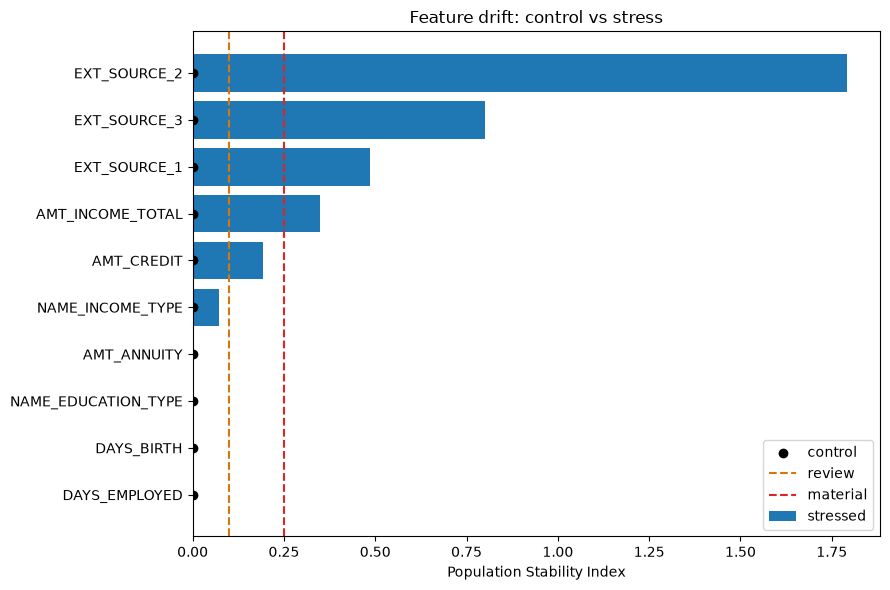

In [4]:
comparison = control_report[["feature", "psi"]].merge(
    stress_report[["feature", "psi", "status"]], on="feature", suffixes=("_control", "_stress")
)
comparison = comparison.sort_values("psi_stress", ascending=True)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(comparison["feature"], comparison["psi_stress"], label="stressed")
ax.scatter(comparison["psi_control"], comparison["feature"], color="black", label="control")
ax.axvline(0.10, color="#d97706", linestyle="--", label="review")
ax.axvline(0.25, color="#dc2626", linestyle="--", label="material")
ax.set(xlabel="Population Stability Index", title="Feature drift: control vs stress")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Score drift and model behavior

Input drift matters most when it changes the distribution of decisions or model performance. Score
PSI is available immediately; realized performance requires later-arriving outcomes.

In [5]:
champion = joblib.load(PROJECT_ROOT / "models" / "logistic_champion.joblib")
challenger = joblib.load(PROJECT_ROOT / "models" / "xgboost_challenger.joblib")

score_rows = []
for name, model in {"champion": champion, "challenger": challenger}.items():
    reference_score = model.predict_proba(reference[list(MODEL_FEATURES)])[:, 1]
    control_score = model.predict_proba(control[list(MODEL_FEATURES)])[:, 1]
    stressed_score = model.predict_proba(stressed[list(MODEL_FEATURES)])[:, 1]
    score_rows.append(
        {
            "model": name,
            "control_score_psi": numeric_psi(reference_score, control_score),
            "stress_score_psi": numeric_psi(reference_score, stressed_score),
            "control_mean_pd": control_score.mean(),
            "stress_mean_pd": stressed_score.mean(),
        }
    )

score_monitor = pd.DataFrame(score_rows).set_index("model")
score_monitor.style.format("{:.4f}")

,control_score_psi,stress_score_psi,control_mean_pd,stress_mean_pd
model,,,,
champion,0.0001,0.2908,0.0811,0.1052
challenger,0.0004,0.3727,0.0812,0.1063


In [6]:
material_features = stress_report.loc[stress_report["status"] == "material", "feature"].tolist()
print("Materially shifted features:", material_features)
for model_name, row in score_monitor.iterrows():
    print(
        f"{model_name}: control PSI={row['control_score_psi']:.3f}, "
        f"stress PSI={row['stress_score_psi']:.3f}, "
        f"mean PD {row['control_mean_pd']:.3f} -> {row['stress_mean_pd']:.3f}"
    )

Materially shifted features: ['EXT_SOURCE_2', 'EXT_SOURCE_3', 'EXT_SOURCE_1', 'AMT_INCOME_TOTAL']
champion: control PSI=0.000, stress PSI=0.291, mean PD 0.081 -> 0.105
challenger: control PSI=0.000, stress PSI=0.373, mean PD 0.081 -> 0.106


The labels attached to the synthetic applications are retained only for sensitivity analysis. In a
live system, defaults mature months later, creating a monitoring lag.

In [7]:
performance_rows = []
for name, model in {"champion": champion, "challenger": challenger}.items():
    for window_name, window in {"control": control, "stressed_inputs": stressed}.items():
        probability = model.predict_proba(window[list(MODEL_FEATURES)])[:, 1]
        performance_rows.append(
            {"model": name, "window": window_name, **evaluate_binary_classifier(window["TARGET"], probability)}
        )

pd.DataFrame(performance_rows).set_index(["model", "window"]).style.format("{:.4f}")

## 4. Monitoring response matrix

| Signal | Immediate action | Escalation |
|---|---|---|
| PSI < 0.10 | log and continue | none |
| PSI 0.10–0.25 | investigate data/process change | owner review if persistent |
| PSI ≥ 0.25 | validate pipeline and restrict change | model-risk review / retraining assessment |
| score drift + decision-rate change | check policy impact | business and compliance review |
| realized AUC/calibration breach | quantify customer and loss impact | rollback or controlled retraining |

Monitoring should record window dates, population definitions, model version, thresholds, alert
owner, resolution, and whether the root cause was data quality, portfolio mix, policy, or economy.

**Interpretation and limitations:** the quiet control window checks false-alarm behavior, while the
stressed window shows whether intentionally shifted inputs propagate into model scores. The scenario
is deterministic sensitivity analysis—not a macroeconomic forecast—and retained historical labels
are not valid future outcomes under a changed world. PSI also depends on reference bins and sample
size. A production framework should combine data-quality rules, feature/score drift, decision-rate
monitoring, delayed outcome performance, calibration, fairness, overrides, complaints, and incident
management with named owners and tested rollback procedures.

In this run, the unmodified control is stable for both models (score PSI approximately **0.000**).
Under stress, champion and challenger score PSI rise to roughly **0.291** and **0.373**, respectively,
while mean predicted PD increases from about **8.1%** to **10.5–10.6%**. Four inputs are materially
shifted. The appropriate response is investigation and retraining assessment—not automatic retraining
from PSI alone—followed by outcome-based validation when labels mature.